# Phase 2 — Member 1: Simple MLP Baseline for Flight Delay Prediction

Read-only results summary for the **simple MLP baseline (one-hot inputs)**. Training is done by
`scripts/train_mlp_baseline.py`; this notebook only loads its saved outputs (D-302).

Protocol (D-301, same as Phase 1): fit January–July, choose the epoch on August, refit
January–August, score September–October once next to the Phase 1 Logistic Regression.
November–December stays sealed and is never read.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path('..').resolve()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import pandas as pd  # noqa: E402
import torch  # noqa: E402
from IPython.display import Image, display  # noqa: E402

from flight_delay.models.mlp_training import predict_flight_delays  # noqa: E402

model_dir = ROOT / 'models' / 'phase2' / 'member1'
fig_dir = ROOT / 'reports' / 'figures' / 'phase2_member1'
results_dir = ROOT / 'reports' / 'results' / 'phase2_member1'
print('PyTorch version:', torch.__version__)

PyTorch version: 2.15.0


## 1. Data periods and inputs

In [2]:
metadata = json.loads((model_dir / 'run_metadata.json').read_text())
for k in ['stage_a_fit_period', 'stage_a_tuning_period', 'final_training_period', 'evaluation_period']:
    print(f'{k:24s} {metadata[k]}')
print('Rows:', metadata['rows'])
print('Delay rate:', {k: round(v, 3) for k, v in metadata['positive_rate'].items()})
print('Inputs:', len(metadata['numeric_features']), 'numeric +',
      metadata['one_hot_feature_count'], 'one-hot =', metadata['total_input_dim'])
print('Holdout accessed:', metadata['holdout_accessed'])

stage_a_fit_period       2013-01-01 to 2013-07-31
stage_a_tuning_period    2013-08-01 to 2013-08-31
final_training_period    2013-01-01 to 2013-08-31
evaluation_period        2013-09-01 to 2013-10-31
Rows: {'fit': 188971, 'tune': 28756, 'final': 217727, 'eval': 55628}
Delay rate: {'fit': 0.266, 'tune': 0.246, 'final': 0.264, 'eval': 0.157}
Inputs: 49 numeric + 966 one-hot = 1015
Holdout accessed: False


## 2. Architecture

Input (1,015) → Linear(128) → ReLU → Dropout(0.3) → Linear(64) → ReLU → Dropout(0.2) → Linear(1)
(logits; the sigmoid is applied only when producing probabilities).

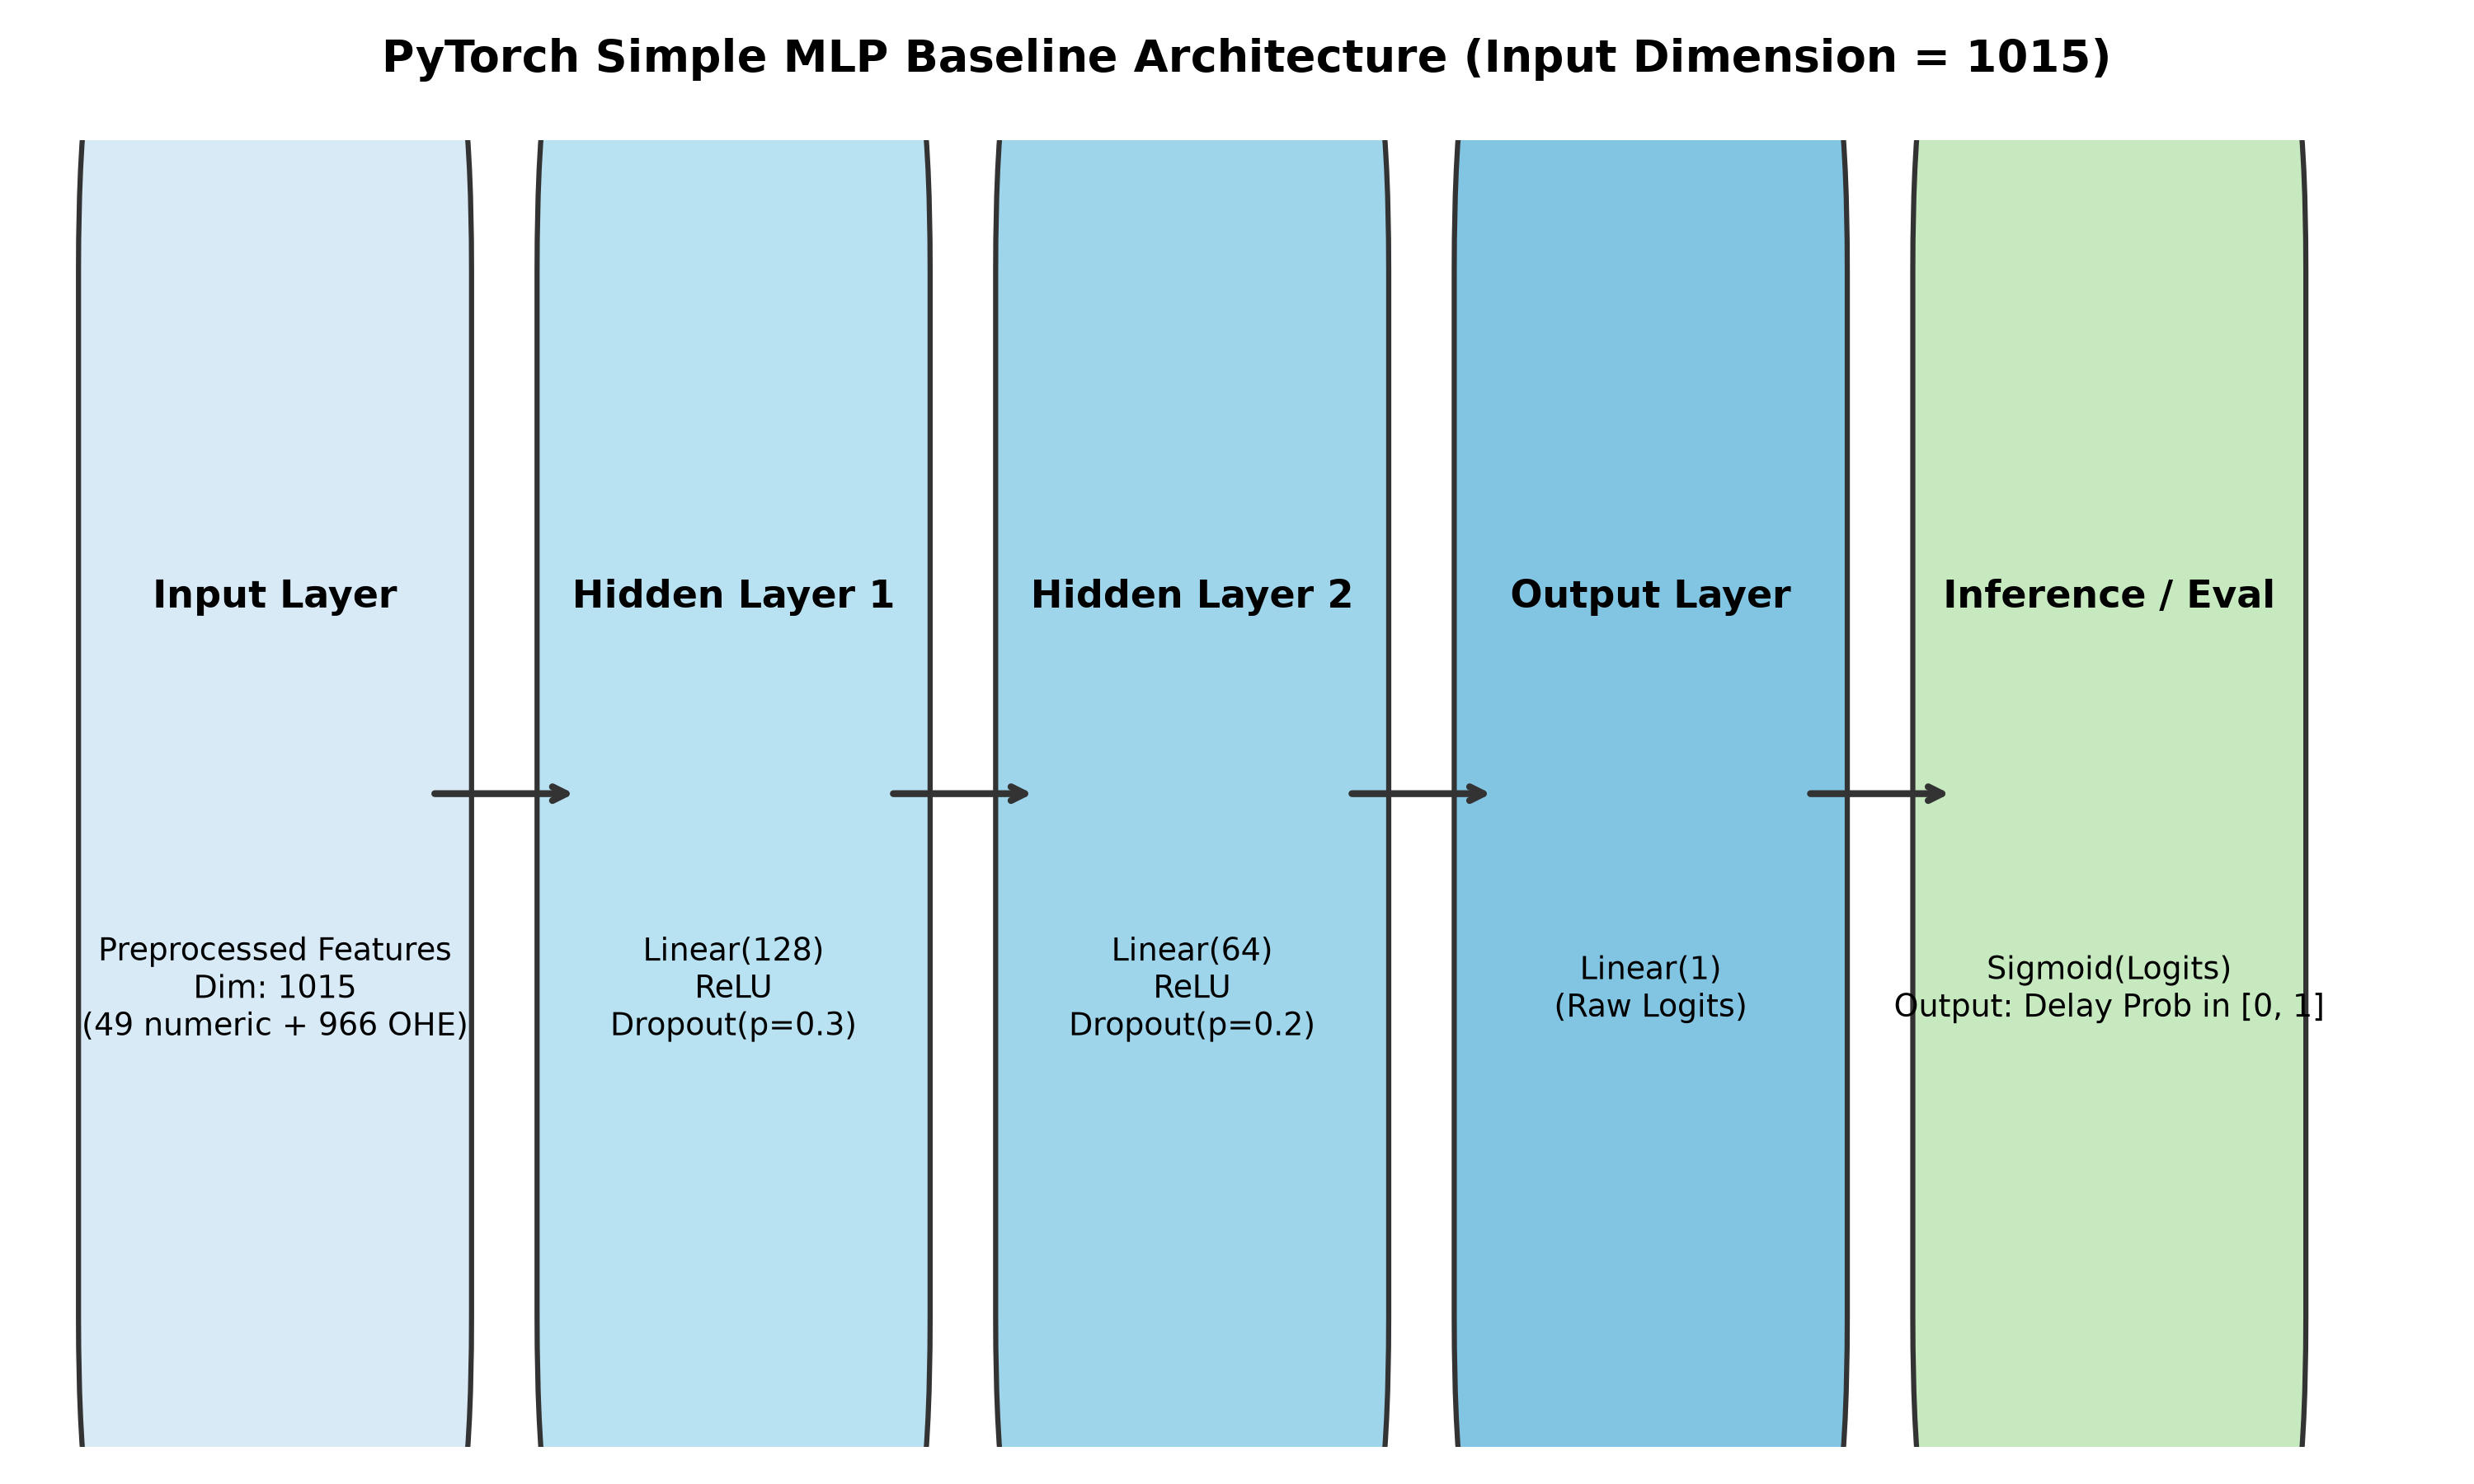

In [3]:
arch_fig_path = ROOT / 'reports' / 'figures' / 'phase2_member1' / 'mlp_architecture.png'
display(Image(filename=str(arch_fig_path)))

## 3. Epoch selection on August (Stage A)

Adam (lr 0.001), batch 256, unweighted BCE, early stopping with patience 5 on August PR-AUC.

,epoch,train_loss,valid_loss,valid_pr_auc,valid_roc_auc,valid_brier,valid_ece
0,1,0.52416,0.54175,0.37957,0.66682,0.17775,0.05285
1,2,0.50935,0.55518,0.37321,0.66670,0.18529,0.07477
2,3,0.50248,0.56335,0.35238,0.66046,0.18908,0.07470
3,4,0.49736,0.57959,0.33872,0.65619,0.19603,0.08893
4,5,0.49172,0.61123,0.34619,0.66515,0.20263,0.11449
5,6,0.48771,0.59968,0.34576,0.66500,0.19780,0.10502


Selected epoch: 1 | August PR-AUC: 0.3796 | Phase 1 on August: LR 0.4007, XGBoost 0.3960 (D-201)
Stage B refit on Jan-Aug: [0.5244856877766821]


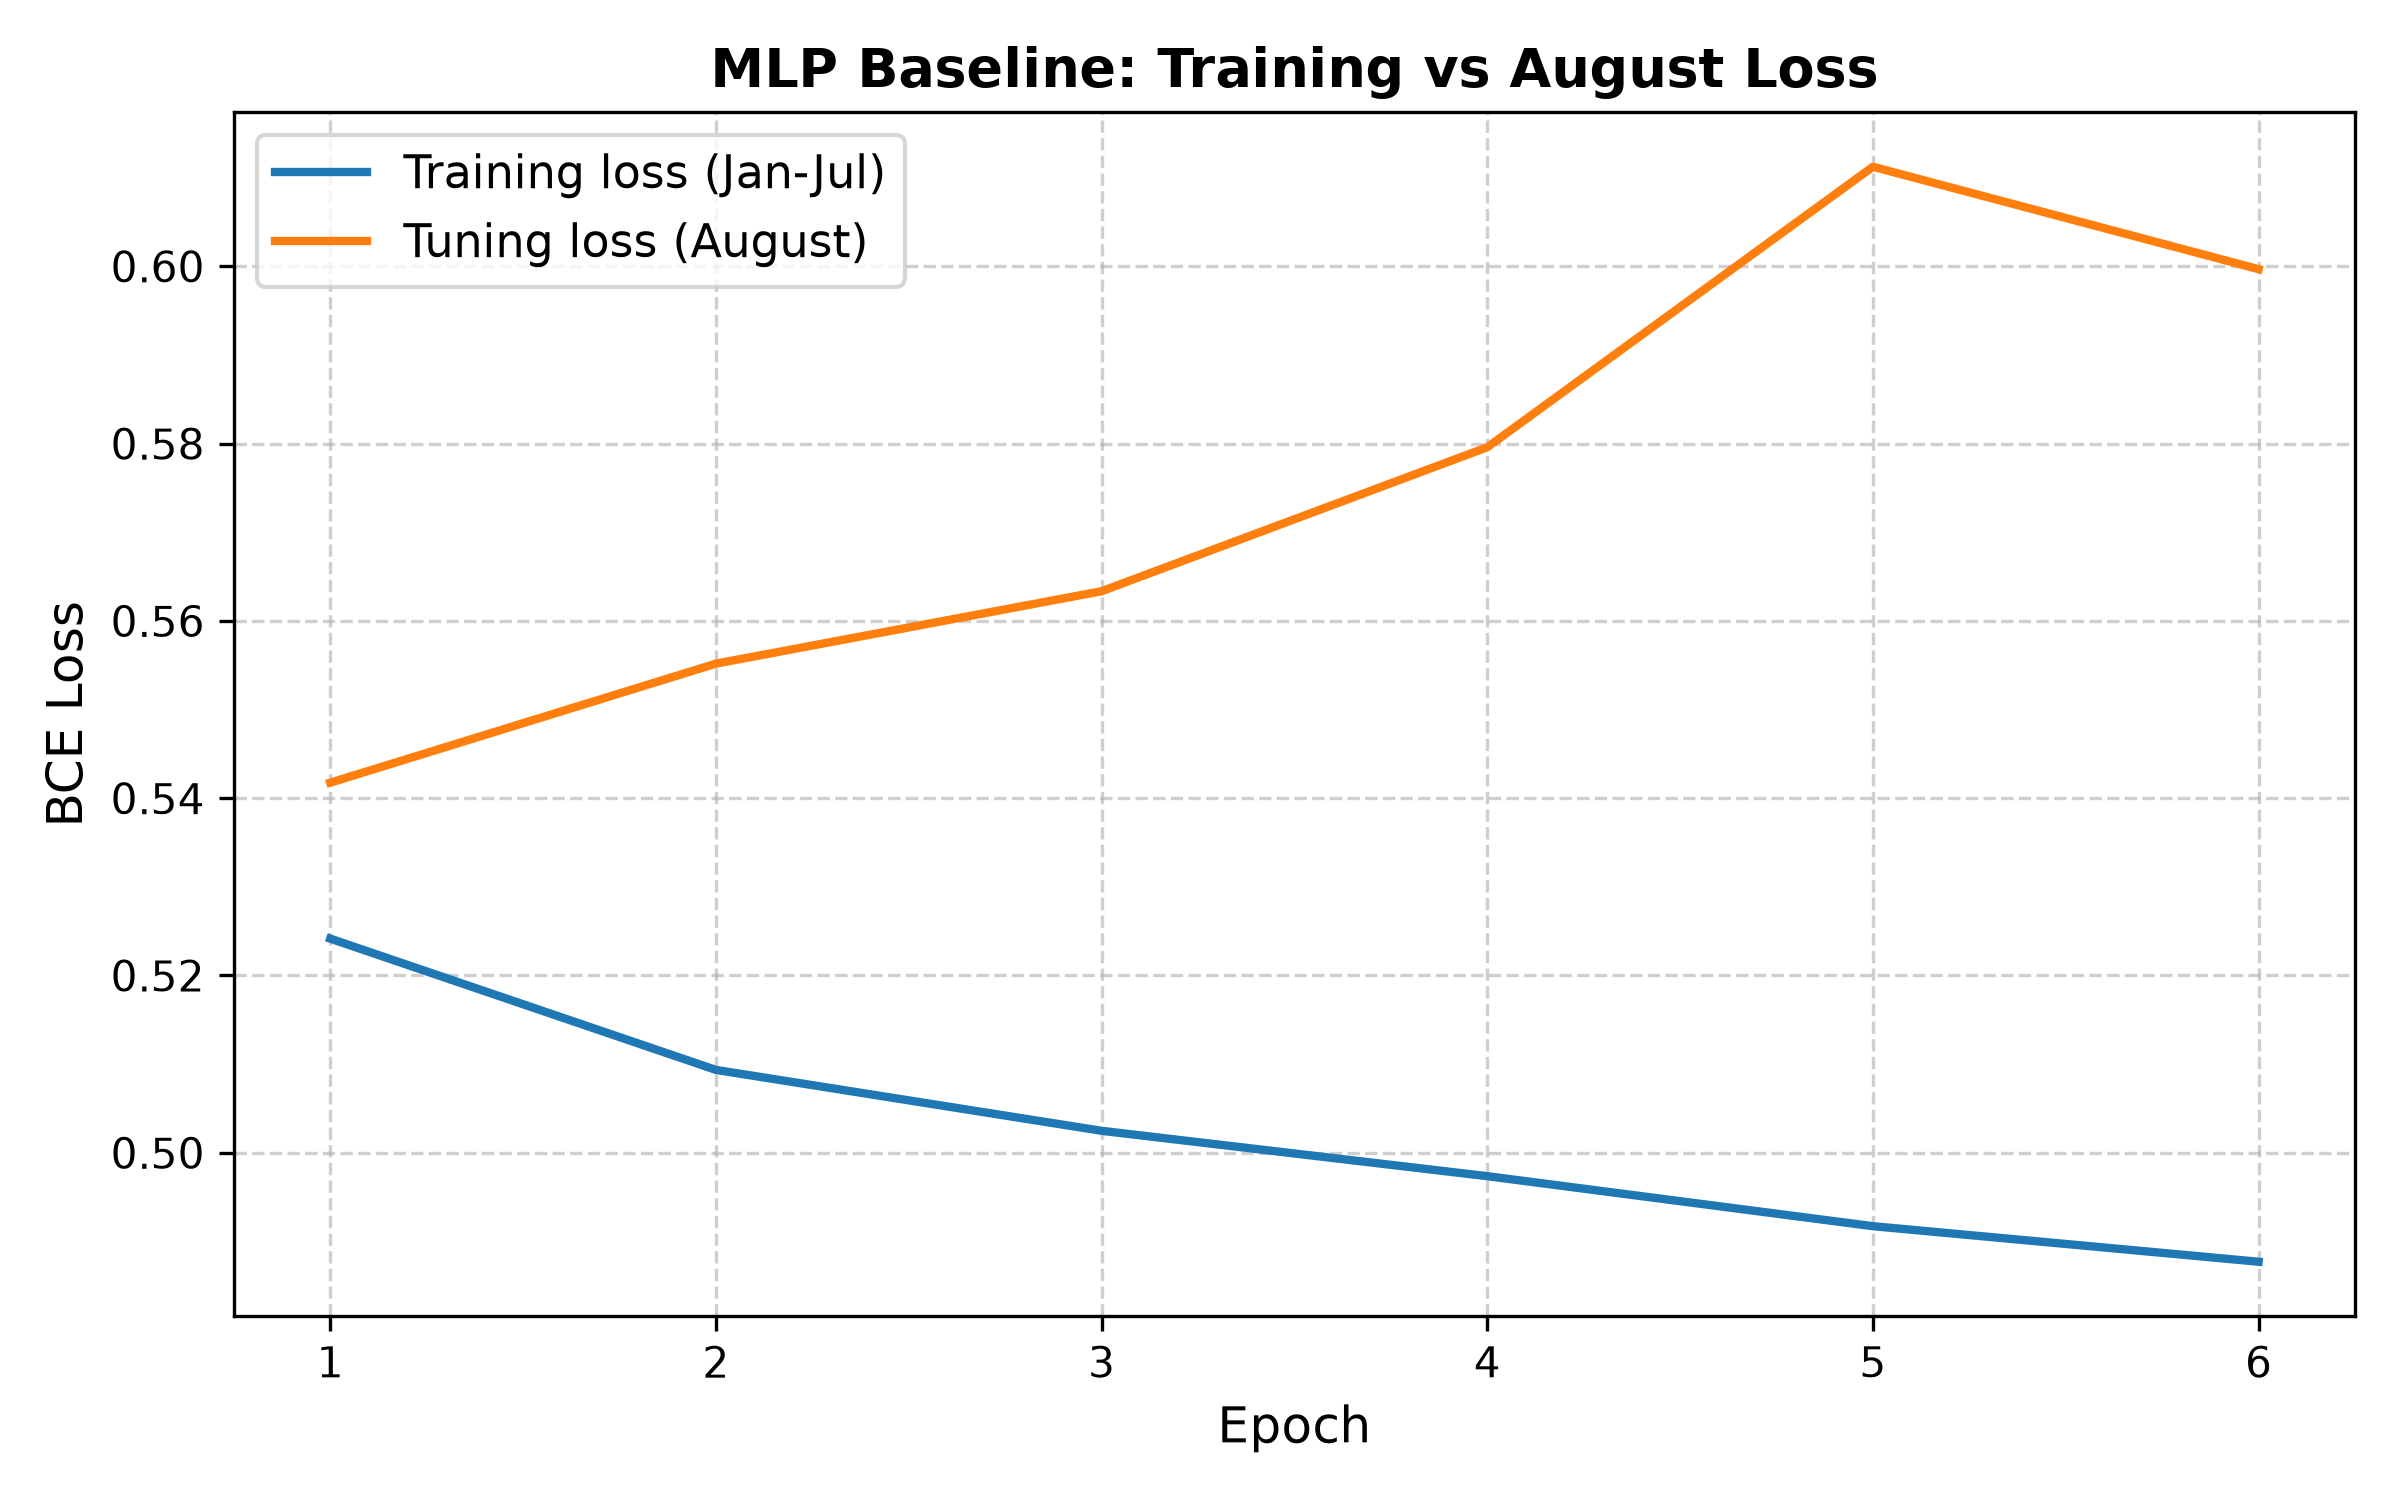

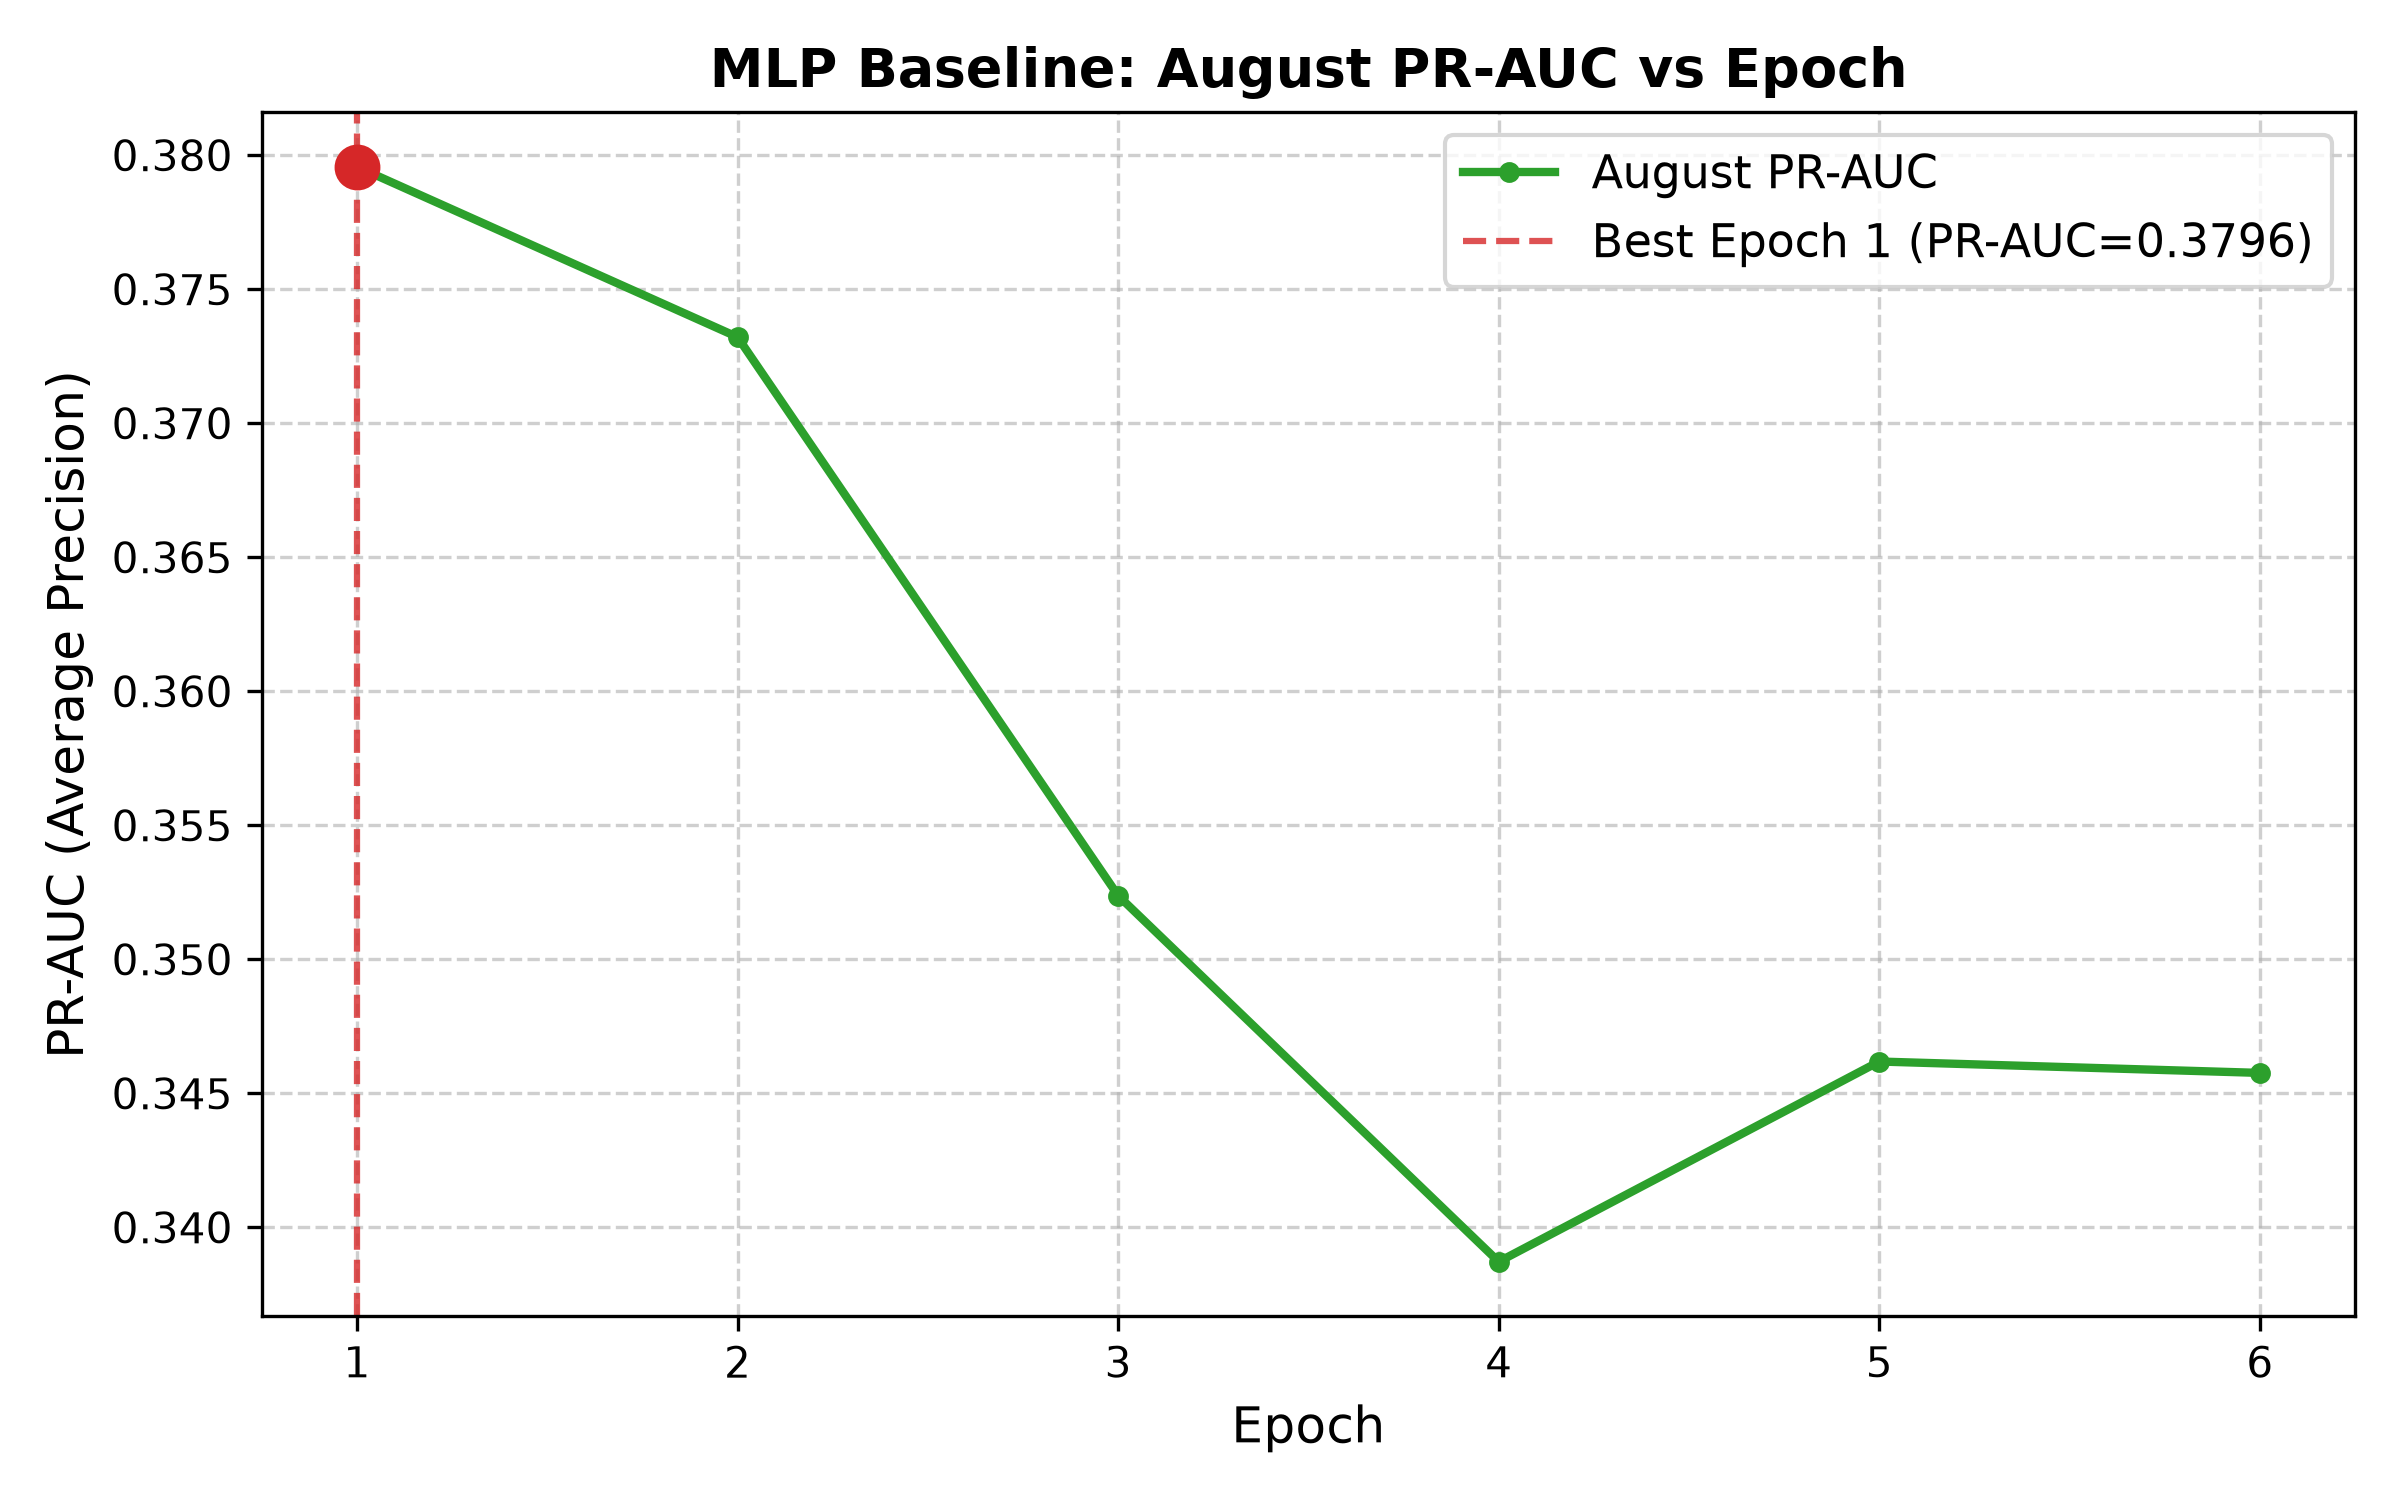

In [4]:
history = json.loads((model_dir / 'training_history.json').read_text())
display(pd.DataFrame(history['stage_a_jan_jul_vs_august']).round(5))
print('Selected epoch:', metadata['best_epoch'],
      '| August PR-AUC:', round(metadata['august_pr_auc_at_best_epoch'], 4),
      '| Phase 1 on August: LR 0.4007, XGBoost 0.3960 (D-201)')
print('Stage B refit on Jan-Aug:', history['stage_b_jan_aug_refit']['train_loss'])
display(Image(filename=str(fig_dir / 'loss_curve.png'), width=600))
display(Image(filename=str(fig_dir / 'august_pr_auc_vs_epoch.png'), width=600))

## 4. September–October, scored once

Both models were trained on January–August; neither was tuned on September–October.

In [5]:
comparison = pd.read_csv(results_dir / 'model_comparison.csv')
display(comparison.drop(columns='notes').round(4))
metrics = json.loads((model_dir / 'validation_metrics.json').read_text())
print('Diagnostic at threshold 0.50 (not an operating point): '
      f"precision {metrics['precision']:.3f}, recall {metrics['recall']:.3f}, "
      f"confusion matrix {metrics['confusion_matrix']}")

,model,pr_auc,roc_auc,brier_score,ece_10,mean_predicted_probability,positive_rate
0,"Logistic Regression (Phase 1 final, raw)",0.2896,0.6800,0.1855,0.2334,0.3904,0.157
1,"MLP baseline (Phase 2 Member 1, raw)",0.2773,0.6679,0.1344,0.0856,0.2426,0.157


Diagnostic at threshold 0.50 (not an operating point): precision 0.420, recall 0.084, confusion matrix [[45886, 1011], [7999, 732]]


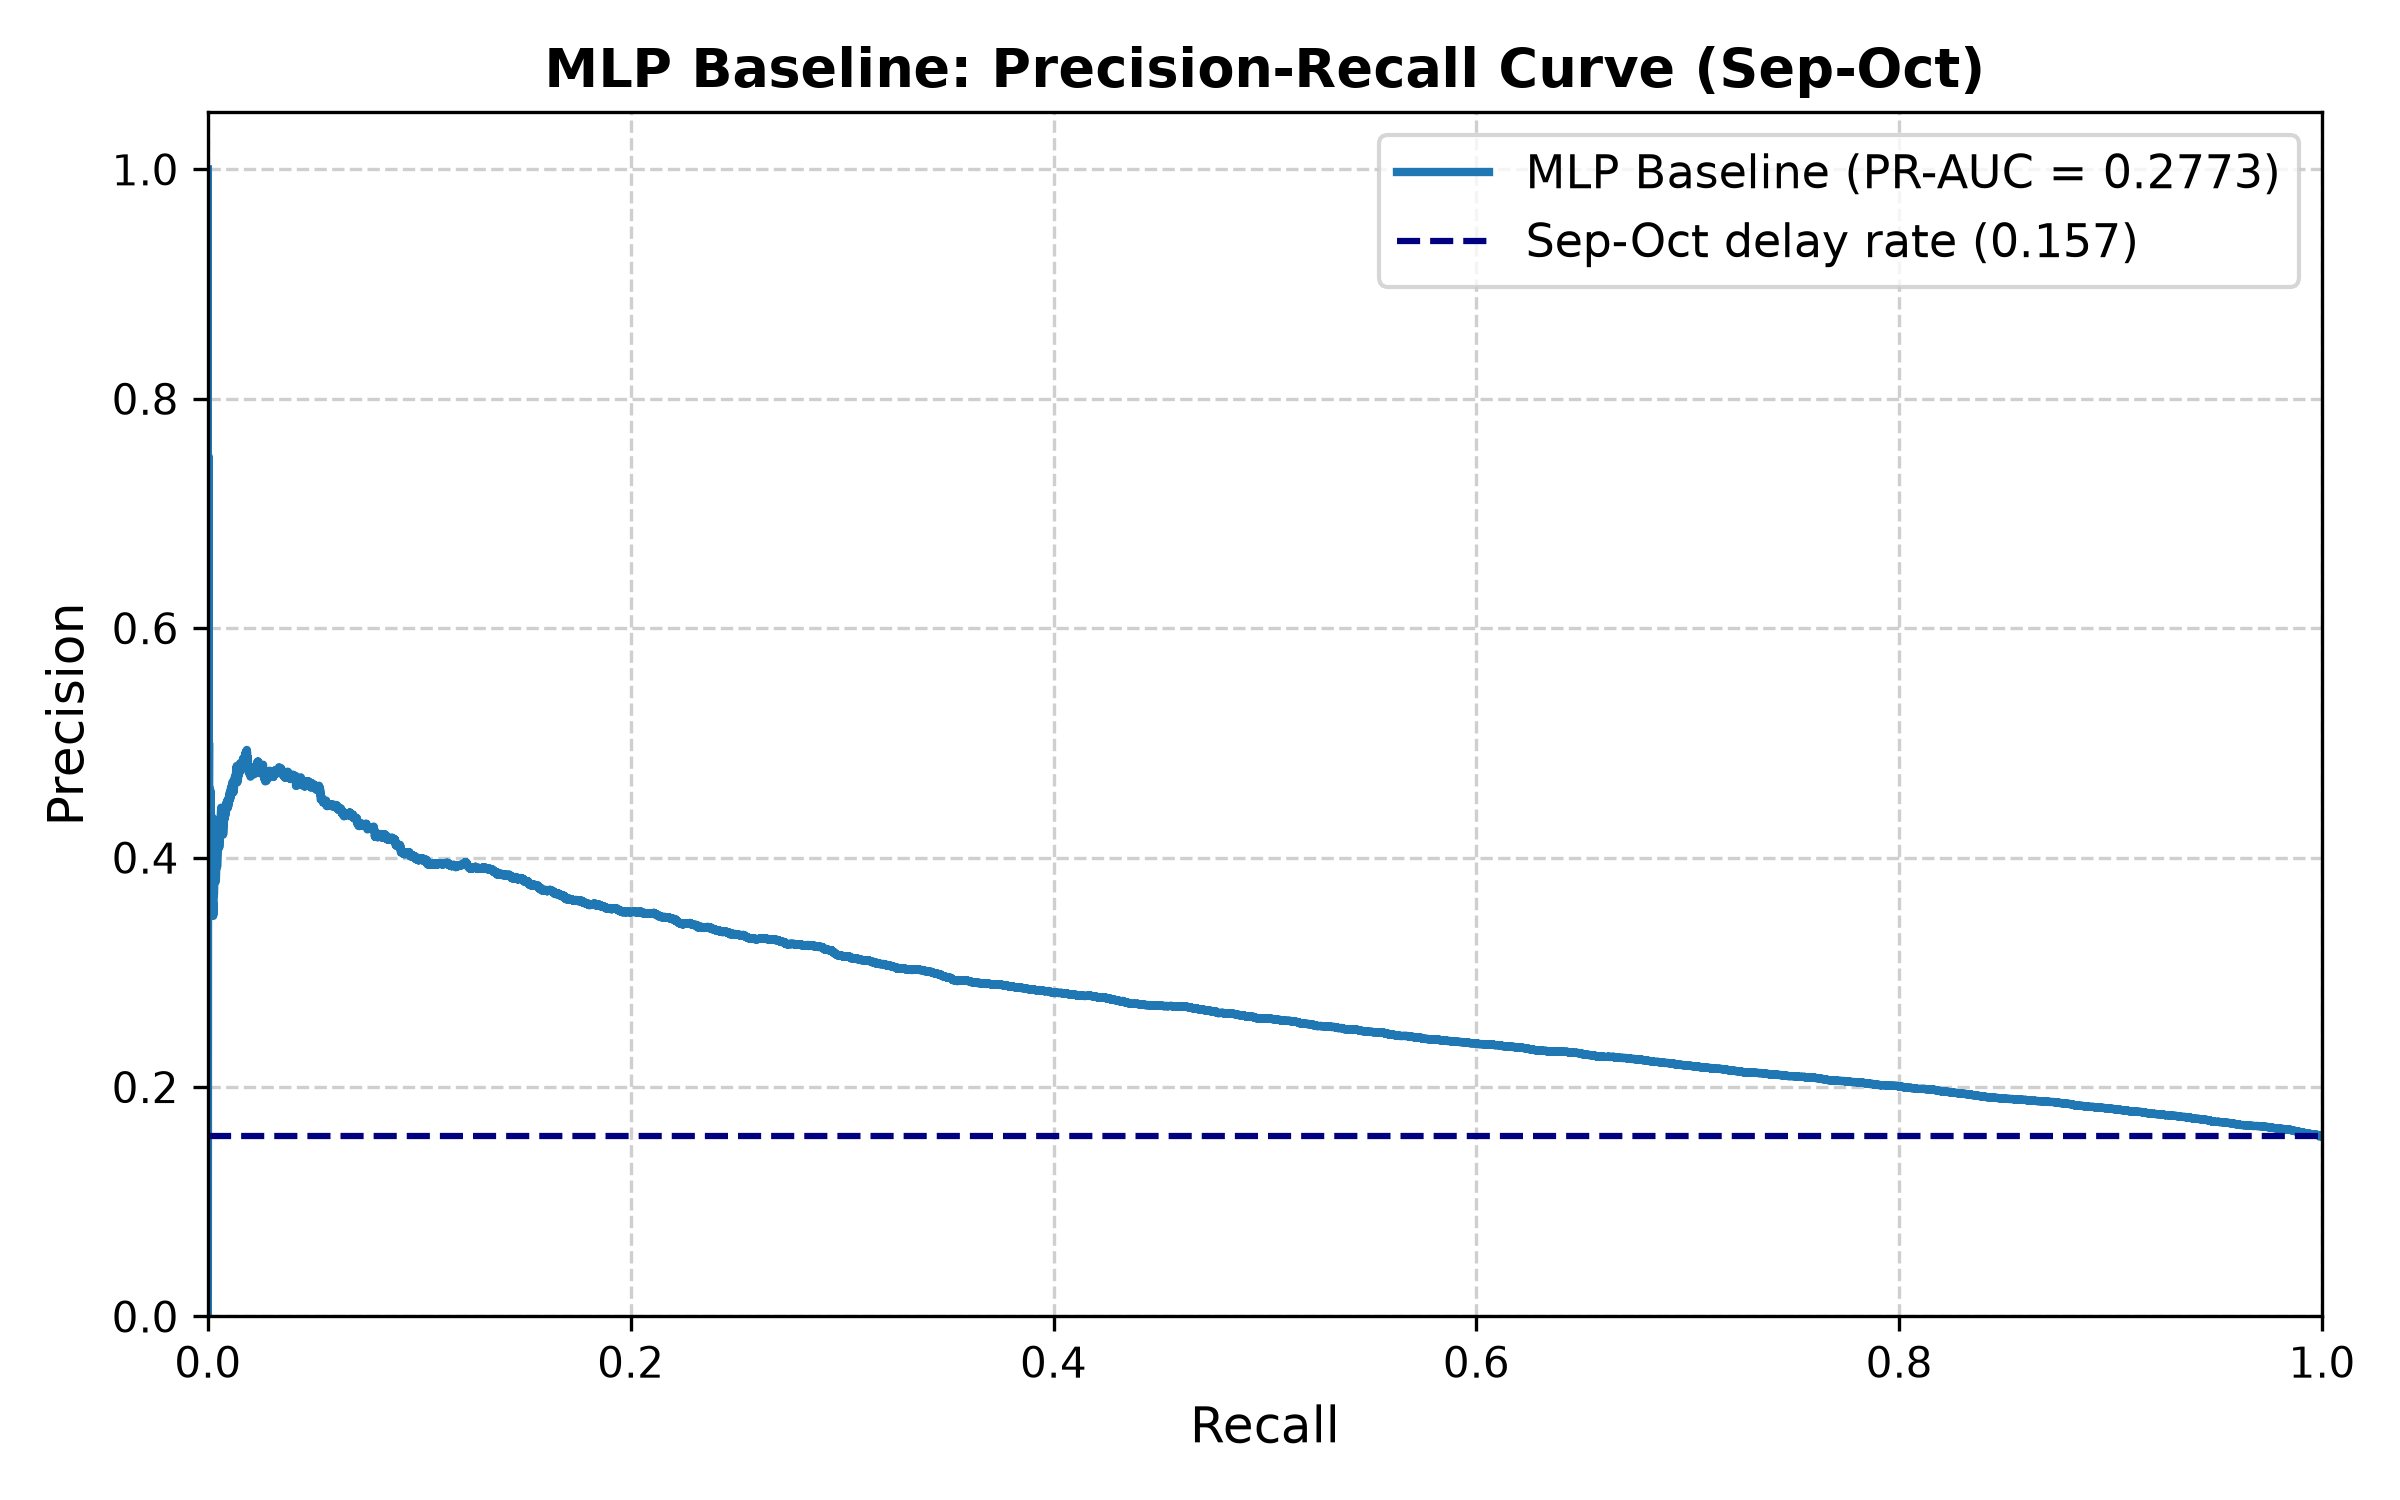

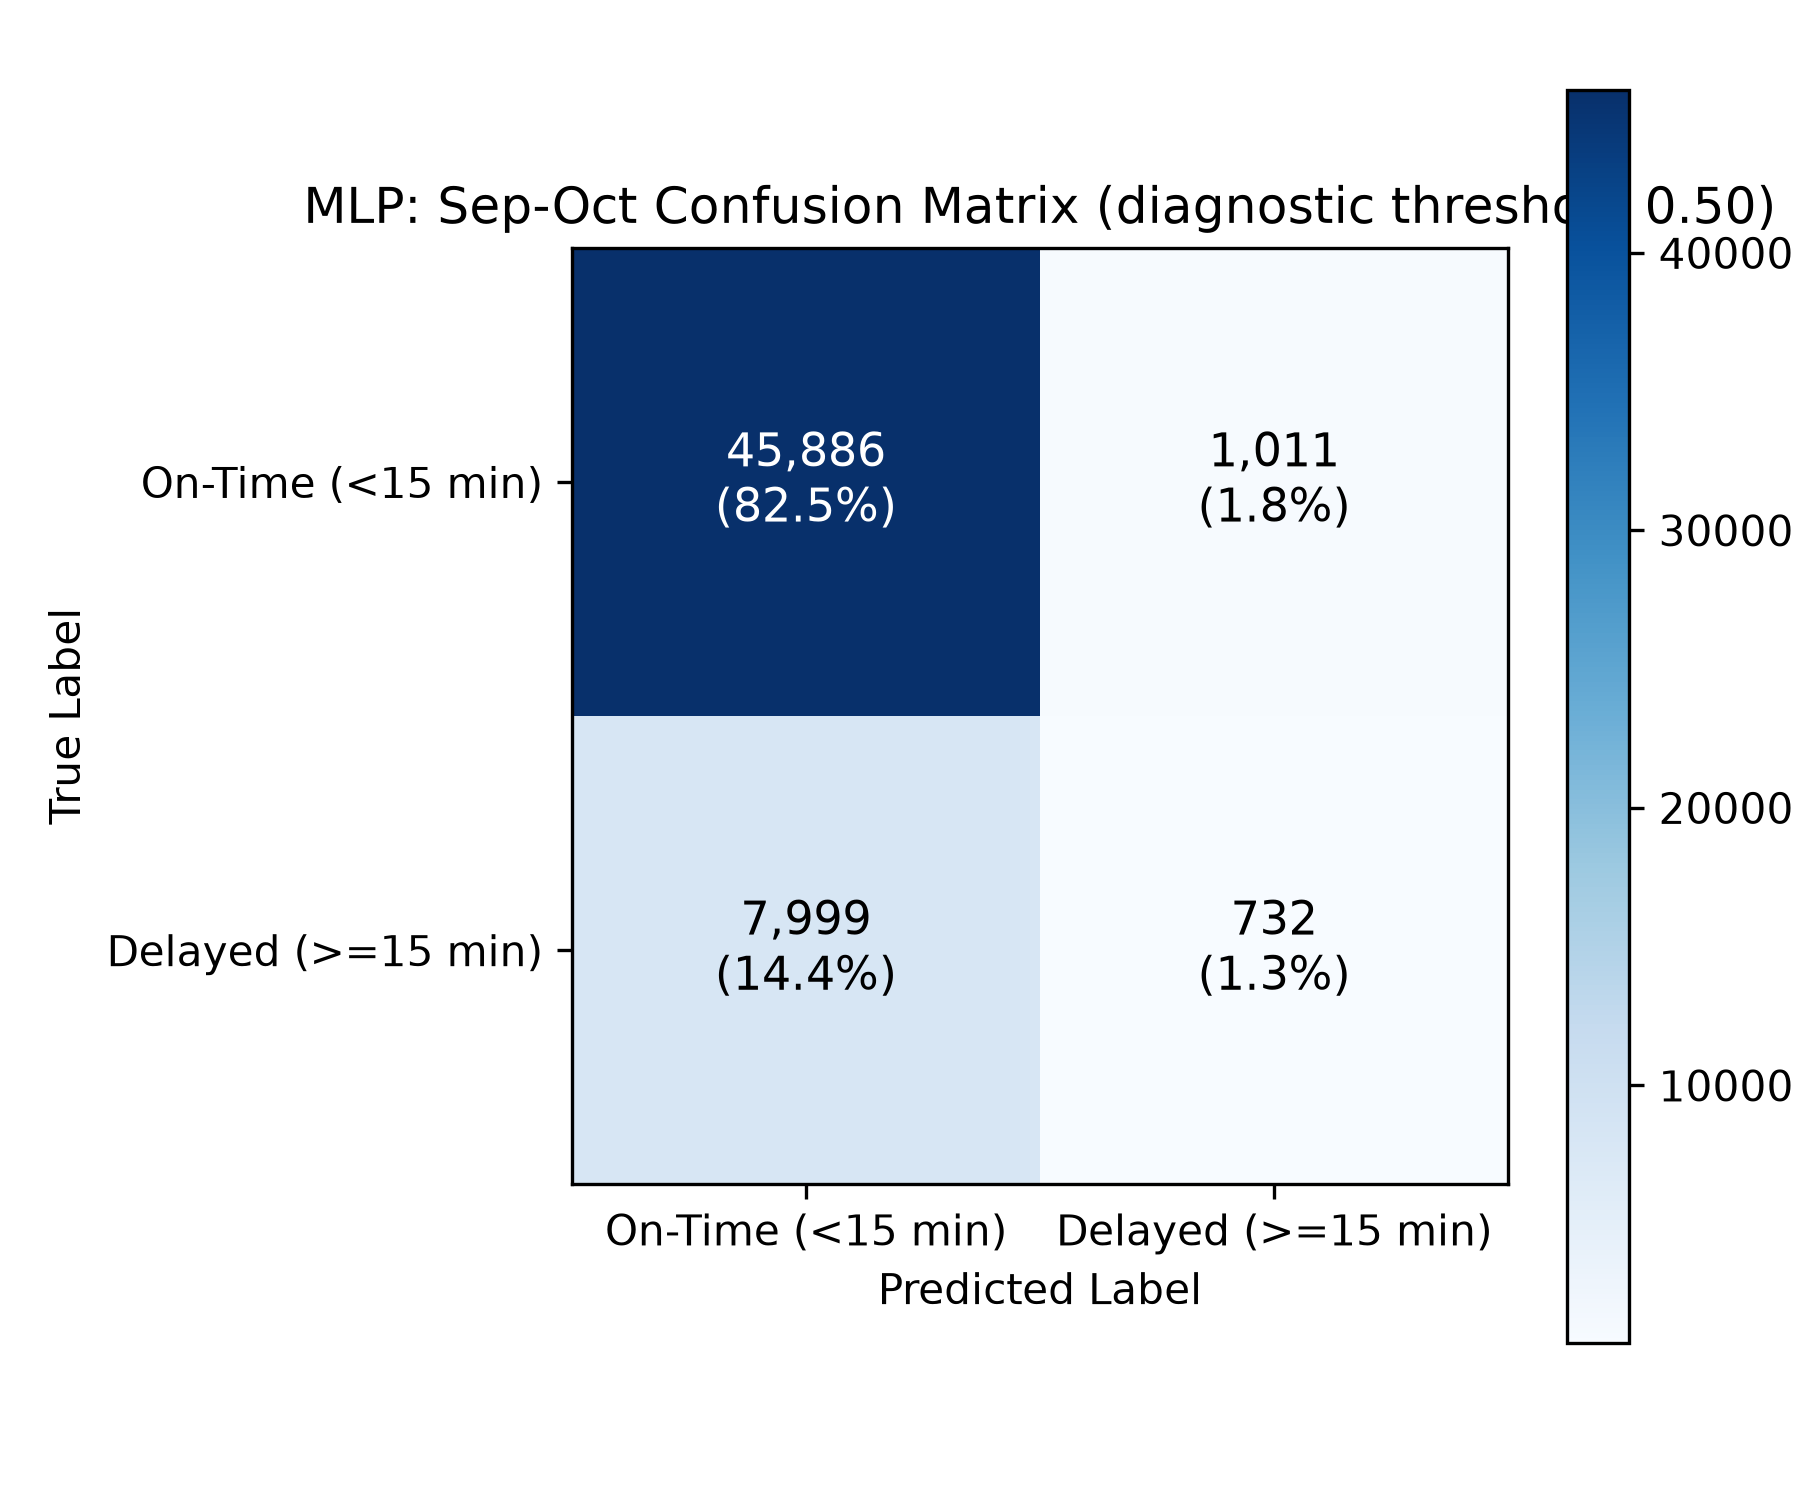

In [6]:
display(Image(filename=str(fig_dir / 'precision_recall_curve.png'), width=600))
display(Image(filename=str(fig_dir / 'confusion_matrix.png'), width=450))

## 5. Reading

* **Ranking:** the MLP is slightly worse than the Phase 1 Logistic Regression on the same flights
  (PR-AUC 0.277 vs 0.290, ROC-AUC 0.668 vs 0.680), and on August too (0.380 vs 0.401).
* **Calibration:** the MLP's raw probabilities are closer to the truth than the class-weighted
  Logistic Regression's, but still too high (mean 0.243 vs a 0.157 delay rate). Calibration is
  Member 5's task.
* **Overfitting:** the best epoch is the first; August loss rises after it. Tuning and embeddings
  are Member 3's task.

## 6. Reusable inference

`predict_flight_delays()` loads the saved preprocessing and weights and scores flights.

In [7]:
sample_df = pd.read_parquet(ROOT / 'data' / 'processed' / 'valid.parquet').head(10)
probs, preds = predict_flight_delays(model_dir, sample_df, threshold=0.50, device='cpu')
display(pd.DataFrame({
    'carrier': sample_df['carrier'],
    'origin': sample_df['origin'],
    'dest': sample_df['dest'],
    'true_delayed': sample_df['is_delayed'],
    'pred_probability': probs.round(3),
    'pred_label': preds,
}))

,carrier,origin,dest,true_delayed,pred_probability,pred_label
0,B6,JFK,BQN,0,0.217,0
1,B6,JFK,SYR,1,0.251,0
2,UA,EWR,IAH,0,0.047,0
3,AA,JFK,MIA,0,0.033,0
4,B6,JFK,BQN,0,0.070,0
5,UA,EWR,TPA,0,0.056,0
6,AA,LGA,MIA,0,0.022,0
7,B6,EWR,MCO,0,0.049,0
8,EV,LGA,IAD,0,0.066,0
9,DL,LGA,ATL,0,0.036,0
